# Actividades 3 y 4. Limpieza, ingeniería de variables, partición de datos y modelo base

## Proyecto Integrador, Fase 2: preprocesamiento del rendimiento académico en lengua portuguesa de estudiantes de secundaria

Andrés Felipe Ricaurte Cortés

Maestría en Inteligencia Artificial
Universidad de La Salle, Bogotá, Colombia
Asignatura: Ciencia de Datos, Grupo 2

Noviembre de 2026

## Contenido

1. Introducción
2. Marco conceptual: datos faltantes, fuga de datos y modelo base
3. Preparación del entorno y verificación de concordancia con la Fase 1
4. Limpieza e imputación de datos
5. Ingeniería de variables
6. Partición de los datos
7. Codificación y escalamiento sin fuga de datos
8. Modelo base (baseline)
9. Conclusiones y preparación de la Fase 3
10. Referencias

## 1. Introducción

Este cuaderno corresponde a la segunda fase del Proyecto Integrador (Actividades 3 y 4) y trabaja con los mismos datos del cuaderno anterior: el archivo de lengua portuguesa del conjunto Student Performance (Cortez y Silva, 2008), con 649 estudiantes y 33 variables. En la Fase 1 el análisis exploratorio dejó varias decisiones pendientes y una lista de tareas para esta fase. Aquí se resuelven una por una: qué hacer con los 15 estudiantes con nota final igual a cero y con el único G1 sospechoso, cómo tratar los valores atípicos de las ausencias, qué variables derivadas crear, cómo partir los datos, cómo codificar y escalar sin contaminar la validación con información del entrenamiento y, por último, qué rendimiento mínimo debe superar cualquier modelo de la Fase 3.

Se mantienen las mismas convenciones de la Fase 1: la variable objetivo de regresión es G3, la de clasificación es aprobado (G3 de 10 o más) y se conservan las listas de variables cuantitativas, ordinales y nominales. Un punto que se tuvo presente durante todo el cuaderno es el orden de las operaciones. Todo lo que se calcula a partir de los datos (medianas, medias, categorías) se ajusta solo con el conjunto de entrenamiento, así que antes de esos pasos se hace la partición. Las transformaciones que no aprenden nada de los datos (por ejemplo, sumar dos columnas) se pueden hacer antes sin problema.

## 2. Marco conceptual: datos faltantes, fuga de datos y modelo base

### 2.1 Mecanismos de datos faltantes

Antes de imputar hay que preguntarse por qué faltan los datos. Rubin (1976) distingue tres mecanismos, que también explican Little y Rubin (2019). Los datos son faltantes completamente al azar (MCAR) cuando la probabilidad de que falten no depende de ninguna variable, ni observada ni no observada; en ese caso eliminar o imputar introduce poco sesgo. Son faltantes al azar (MAR) cuando esa probabilidad depende de otras variables que sí se observaron, y entonces se puede imputar usando esas variables. Son faltantes no al azar (MNAR) cuando la probabilidad depende del propio valor que falta, caso en el que ninguna imputación basada solo en lo observado es plenamente confiable. No hay una prueba definitiva que distinga MAR de MNAR con los datos disponibles; lo que se puede hacer es comparar el grupo con dato faltante contra el resto en las demás variables y razonar sobre el contexto. Eso es lo que se hace en la sección 4.

Las opciones de tratamiento que pide la guía son eliminar las filas, imputar con una medida de tendencia central (media o mediana), o imputar con modelos como KNNImputer o IterativeImputer. La media y la mediana son simples pero ignoran las demás variables; KNNImputer y IterativeImputer aprovechan la relación con otras variables y son más apropiados cuando el mecanismo es MAR.

### 2.2 Fuga de datos

La fuga de datos (data leakage) ocurre cuando la información del conjunto de validación o de prueba se filtra, de forma directa o indirecta, al entrenamiento, y por eso las métricas salen más optimistas de lo que serán en la realidad (Kaufman et al., 2012). Un ejemplo común es calcular la media y la desviación para estandarizar usando todos los datos y después partir: el entrenamiento ya conoce algo de la validación. La regla que se sigue aquí es que cualquier paso que aprenda parámetros (imputadores, escaladores, codificadores) se ajusta únicamente con el entrenamiento y luego se aplica a validación y prueba. Para garantizarlo se usan Pipeline y ColumnTransformer de scikit-learn (Pedregosa et al., 2011), que encapsulan el ajuste y la transformación.

### 2.3 Modelo base y métricas

Un modelo base es una referencia sencilla que fija el rendimiento mínimo que debe superar cualquier modelo más elaborado; si un modelo complejo no mejora al base, no justifica su complejidad. En regresión se reportan el coeficiente de determinación R², la raíz del error cuadrático medio (RMSE) y el error absoluto medio (MAE). En clasificación se toma como clase positiva la de interés práctico, que es reprobar, y se reportan exactitud, precisión (de los que se predicen como reprobados, cuántos lo son), exhaustividad o recall (de los reprobados reales, cuántos se detectan), F1 (la media armónica de precisión y recall) y el área bajo la curva ROC (AUC). Como la clase reprobado es minoritaria (15,4 %), la exactitud por sí sola engaña: un clasificador que dijera siempre aprobado acertaría el 84,6 % de las veces y no detectaría a ningún estudiante en riesgo. Por eso el F1 y el recall de la clase reprobado serán las métricas principales. Las métricas se calculan en entrenamiento y validación para vigilar el sobreajuste; el conjunto de prueba se deja intacto hasta la evaluación final de la Fase 3.

## 3. Preparación del entorno y verificación de concordancia con la Fase 1

Se cargan las mismas librerías, el mismo estilo gráfico y la misma paleta de la Fase 1, además de scikit-learn para la partición, los transformadores y los modelos. La semilla aleatoria queda fija para que los resultados se puedan reproducir. Después de cargar el archivo se reconstruyen las variables de la Fase 1 (aprobado y las listas de variables) y se comprueba que las cifras coinciden con las del cuaderno anterior.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, json, urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from pandas.api.types import is_numeric_dtype

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "legend.frameon": False,
})
AZUL, NARANJA, VERDE, AMARILLO, CELESTE, GRIS = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#B0B0B0"
SEMILLA = 42

RUTA = "data/student-por.csv"
URL = "https://raw.githubusercontent.com/Mfundo-debug/student_performancePor/main/student-por.csv"
if not os.path.exists(RUTA):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, RUTA)

df = pd.read_csv(RUTA)
df["aprobado"] = (df["G3"] >= 10).astype(int)
df["estado"] = df["aprobado"].map({1: "Aprobado", 0: "Reprobado"})

# Listas de variables, iguales a las de la Fase 1
cuant = ["age", "failures", "absences", "G1", "G2", "G3"]
ordinales = ["Medu", "Fedu", "traveltime", "studytime", "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
nominales = [c for c in df.columns if not is_numeric_dtype(df[c]) and c != "estado"]

# Verificación de concordancia con la Fase 1
assert df.shape == (649, 35)  # 33 originales + aprobado + estado
assert round(df["G3"].mean(), 2) == 11.91 and round(df["G3"].std(), 2) == 3.23
assert df["aprobado"].sum() == 549 and (df["G3"] == 0).sum() == 15 and len(nominales) == 17
assert df.isna().sum().sum() == 0 and df.drop(columns="estado").duplicated().sum() == 0
print("Filas y columnas originales:", df.shape[0], "y 33")
print(f"Nota final: media {df['G3'].mean():.2f}, desviación {df['G3'].std():.2f}")
print(f"Aprobados: {df['aprobado'].sum()} ({df['aprobado'].mean() * 100:.1f} %), reprobados: {(1 - df['aprobado']).sum()}")
print("Celdas vacías:", int(df.isna().sum().sum()), "| Duplicados:", int(df.drop(columns='estado').duplicated().sum()))
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Filas y columnas originales: 649 y 33
Nota final: media 11.91, desviación 3.23
Aprobados: 549 (84.6 %), reprobados: 100
Celdas vacías: 0 | Duplicados: 0
scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


Las verificaciones pasan sin error, así que el archivo de esta fase es idéntico al de la Fase 1: 649 estudiantes, una nota final media de 11,91, 549 aprobados y 15 notas finales iguales a cero.

## 4. Limpieza e imputación de datos

### 4.1 Datos faltantes formales y disfrazados

En la Fase 1 se encontró que no hay celdas vacías, pero también se vio que la nota final igual a cero tenía un comportamiento extraño. Antes de decidir qué hacer, se cuentan los casos sospechosos de forma sistemática: notas en cero y combinaciones raras con las ausencias.

In [2]:
sosp = pd.DataFrame({
    "Regla": ["G3 igual a 0", "G2 igual a 0", "G1 igual a 0", "G3 igual a 0 y ausencias igual a 0",
              "G3 igual a 0 y G2 mayor que 0", "G1 igual a 0 con G3 mayor que 0"],
    "Estudiantes": [int((df.G3 == 0).sum()), int((df.G2 == 0).sum()), int((df.G1 == 0).sum()),
                    int(((df.G3 == 0) & (df.absences == 0)).sum()), int(((df.G3 == 0) & (df.G2 > 0)).sum()),
                    int(((df.G1 == 0) & (df.G3 > 0)).sum())],
}).set_index("Regla")
sosp["% del total"] = (sosp["Estudiantes"] / len(df) * 100).round(2)
display(sosp)
print("Caso con G1 igual a 0 y G3 mayor que 0:")
display(df.loc[(df.G1 == 0) & (df.G3 > 0), ["school", "sex", "age", "absences", "G1", "G2", "G3"]])
print("G2 = 0 siempre coincide con G3 = 0:", bool((df.loc[df.G2 == 0, "G3"] == 0).all()))

,Estudiantes,% del total
Regla,,
G3 igual a 0,15,2.31
G2 igual a 0,7,1.08
G1 igual a 0,1,0.15
G3 igual a 0 y ausencias igual a 0,15,2.31
G3 igual a 0 y G2 mayor que 0,8,1.23
G1 igual a 0 con G3 mayor que 0,1,0.15


Caso con G1 igual a 0 y G3 mayor que 0:


,school,sex,age,absences,G1,G2,G3
0,GP,F,18,4,0,11,11


G2 = 0 siempre coincide con G3 = 0: True


Tabla 1. Casos sospechosos de ser datos faltantes disfrazados. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Formalmente no hay celdas vacías, pero sí hay 16 valores que parecen faltantes escondidos: 15 notas finales iguales a cero (2,31 % de los estudiantes) y un G1 igual a cero. Los 15 ceros de G3 tienen cero ausencias, y de ellos siete también tienen G2 igual a cero, mientras que ocho llegaron al segundo periodo con una nota positiva y terminaron en cero. Además, todo G2 igual a cero coincide con un G3 igual a cero, un patrón coherente con estudiantes que se retiraron en distintos momentos del año. El caso de G1 es distinto: se trata de una estudiante de GP de 18 años con 4 ausencias que sacó 11 en G2 y 11 en G3, por lo que un cero en el primer periodo es poco creíble y parece un error de captura.

### 4.2 Análisis del mecanismo de falta de la nota final igual a cero

Siguiendo la guía, antes de decidir nada sobre estos casos se analiza el mecanismo. Se trata la nota final igual a cero como un dato posiblemente faltante y se compara a esos 15 estudiantes con el resto en las demás variables. Si el grupo de ceros se pareciera al resto en todo, el mecanismo sería compatible con MCAR; si difiere en variables observadas, el mecanismo depende de esas variables (al menos MAR). Para las variables numéricas se usa la prueba U de Mann-Whitney (Mann y Whitney, 1947), que no exige normalidad, y para las binarias la prueba exacta de Fisher, apropiada con grupos pequeños. No hay en scipy una prueba de Little para MCAR, por lo que esta comparación es la alternativa práctica. Como son varias pruebas, se agrega la corrección de Bonferroni.

In [3]:
z, r = df[df.G3 == 0], df[df.G3 > 0]
filas = []
for v in ["age", "failures", "absences", "G1", "studytime", "Medu", "Fedu", "traveltime", "freetime", "goout", "Dalc", "Walc", "health", "famrel"]:
    u, p = stats.mannwhitneyu(z[v], r[v], alternative="two-sided")
    filas.append({"Variable": v, "Prueba": "Mann-Whitney", "Con G3 = 0": f"mediana {z[v].median():.1f}", "Resto": f"mediana {r[v].median():.1f}", "Valor p": p})
for v, cat in [("school", "MS"), ("sex", "M"), ("address", "R"), ("higher", "no"), ("internet", "no"),
               ("schoolsup", "yes"), ("famsup", "yes"), ("paid", "yes"), ("romantic", "yes")]:
    a, b = int((z[v] == cat).sum()), int((r[v] == cat).sum())
    _, p = stats.fisher_exact([[a, len(z) - a], [b, len(r) - b]])
    filas.append({"Variable": f"{v} = {cat}", "Prueba": "Exacta de Fisher", "Con G3 = 0": f"{a / len(z) * 100:.1f} %", "Resto": f"{b / len(r) * 100:.1f} %", "Valor p": p})
tabla_mec = pd.DataFrame(filas).set_index("Variable")
umbral = 0.05 / len(tabla_mec)
tabla_mec["Significativa (Bonferroni)"] = np.where(tabla_mec["Valor p"] < umbral, "Sí", "No")
tabla_mec["Valor p"] = tabla_mec["Valor p"].map(lambda x: f"{x:.2e}")
print(f"Número de pruebas: {len(tabla_mec)} | nivel de Bonferroni: {umbral:.4f}")
tabla_mec

Número de pruebas: 23 | nivel de Bonferroni: 0.0022


,Prueba,Con G3 = 0,Resto,Valor p,Significativa (Bonferroni)
Variable,,,,,
age,Mann-Whitney,mediana 18.0,mediana 17.0,4.04e-04,Sí
failures,Mann-Whitney,mediana 1.0,mediana 0.0,2.09e-06,Sí
absences,Mann-Whitney,mediana 0.0,mediana 2.0,1.25e-05,Sí
G1,Mann-Whitney,mediana 7.0,mediana 11.0,2.51e-08,Sí
studytime,Mann-Whitney,mediana 1.0,mediana 2.0,2.73e-02,No
Medu,Mann-Whitney,mediana 2.0,mediana 2.0,3.73e-01,No
Fedu,Mann-Whitney,mediana 2.0,mediana 2.0,1.89e-02,No
traveltime,Mann-Whitney,mediana 2.0,mediana 1.0,1.02e-01,No
freetime,Mann-Whitney,mediana 3.0,mediana 3.0,2.74e-01,No


Tabla 2. Comparación entre los estudiantes con nota final igual a cero y el resto. Fuente: elaboración propia con datos de Cortez y Silva (2008).

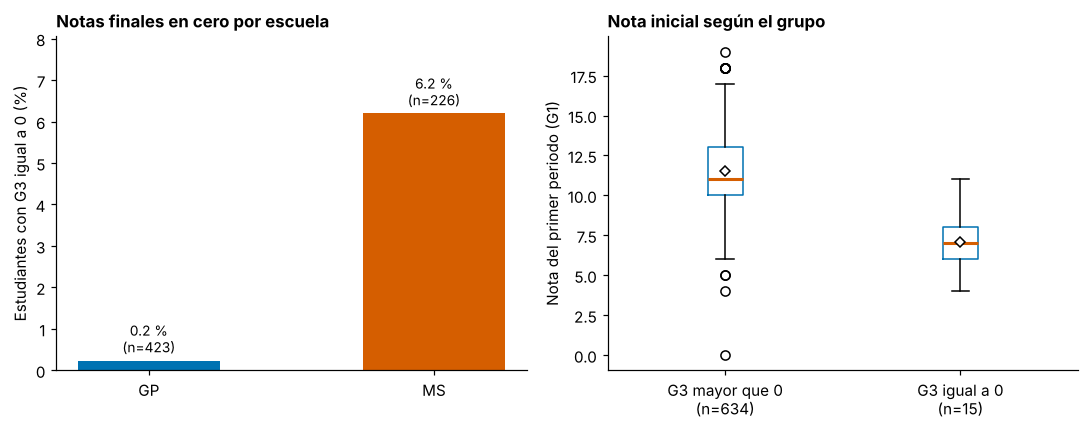

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
por_escuela = df.groupby("school")["G3"].apply(lambda s: (s == 0).mean() * 100)
n_esc = df["school"].value_counts()
ax1.bar(por_escuela.index, por_escuela.values, color=[AZUL, NARANJA], width=0.5)
for i, (esc, val) in enumerate(por_escuela.items()):
    ax1.text(i, val + 0.2, f"{val:.1f} %\n(n={n_esc[esc]})", ha="center", fontsize=9)
ax1.set_ylim(0, por_escuela.max() * 1.3); ax1.set_ylabel("Estudiantes con G3 igual a 0 (%)"); ax1.set_title("Notas finales en cero por escuela")
datos = [r["G1"], z["G1"]]
ax2.boxplot(datos, showmeans=True, boxprops=dict(color=AZUL), medianprops=dict(color=NARANJA, lw=2),
            meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
ax2.set_xticks([1, 2]); ax2.set_xticklabels([f"G3 mayor que 0\n(n={len(r)})", f"G3 igual a 0\n(n={len(z)})"])
ax2.set_ylabel("Nota del primer periodo (G1)"); ax2.set_title("Nota inicial según el grupo")
fig.tight_layout(); plt.show()

Figura 1. Porcentaje de notas finales iguales a cero por escuela y nota del primer periodo en los dos grupos. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. El grupo de ceros no se parece al resto. De los 23 contrastes, cinco son significativos con la corrección de Bonferroni (nivel de 0,0022): la escuela (el 93,3 % de los ceros está en MS frente al 33,4 % del resto), la nota del primer periodo (mediana de 7 frente a 11), las reprobaciones previas (mediana de 1 frente a 0), la edad (18 frente a 17 años) y las ausencias, aunque en este último caso la diferencia es estructural porque los 15 ceros tienen cero ausencias. Otras variables quedan cerca del límite sin superarlo: la zona rural (66,7 % frente a 29,5 %, p de 0,0036), recibir apoyo familiar (26,7 % frente a 62,1 %, p de 0,007) y no querer estudiar educación superior (33,3 % frente a 10,1 %, p de 0,015). Con solo 15 casos la potencia de las pruebas es baja, así que la ausencia de significancia en el resto no prueba que no haya diferencias. En la Figura 1 se ve el mismo patrón: la proporción de ceros es de 0,2 % en GP y de 6,2 % en MS, y casi todos los ceros arrancaron con una nota inicial baja. Esto descarta MCAR, porque la falta depende de variables observadas, y es compatible al menos con MAR. Pero también hay buenas razones para pensar en MNAR: abandonar depende de circunstancias que no están en el archivo y, en el fondo, del propio desempeño que habría tenido el estudiante. Como los datos observados no permiten distinguir una cosa de la otra, ninguna imputación sería confiable para esta variable.

### 4.3 Decisiones sobre la nota final igual a cero y sobre G1

A partir de la evidencia anterior se evaluaron las tres opciones. Imputar la nota final (con la media, KNNImputer o IterativeImputer) significaría inventar la variable que se quiere predecir, y si el cero corresponde a un abandono, cualquier valor imputado sería una nota que el estudiante nunca obtuvo. Mantener el cero tal cual hace que la regresión intente explicar notas que no son de desempeño, con errores enormes que dominan el RMSE. Excluir los casos de la regresión evita ambos problemas, pero para la clasificación el panorama es distinto: que un estudiante abandone o no se presente también es un resultado de riesgo, y justamente el tipo de caso que la escuela quisiera anticipar. Por eso se toma una decisión diferenciada:

1. Se crea un indicador, sin_nota_final, que vale 1 cuando G3 es cero. Este indicador se usa solo para filtrar filas, no como variable predictora, porque se deriva de la variable objetivo y generaría fuga de datos.
2. En la regresión se excluyen esos 15 casos (no tienen una nota real que predecir).
3. En la clasificación se conservan, con la etiqueta reprobado que ya tenían.
4. Más adelante, en la sección 8.1, se mide el efecto de esta decisión para que quede documentado.

Sobre el único G1 igual a cero con G3 positivo, un estudiante que sacó 0 en el primer periodo y 11 en los siguientes es muy poco creíble como nota real; se interpreta como un error de captura y se marca como faltante. Es un caso aislado (0,15 % de las filas), sin patrón que se pueda analizar, así que se asume que su falta es esencialmente aleatoria. Para elegir el método se compara la imputación con la mediana contra una imputación basada en G2, que es la variable más relacionada con G1.

In [5]:
df["sin_nota_final"] = (df["G3"] == 0).astype(int)

mask_g1 = (df["G1"] == 0) & (df["G3"] > 0)
df["G1"] = df["G1"].astype(float)
df.loc[mask_g1, "G1"] = np.nan
print("Valores de G1 marcados como faltantes:", int(mask_g1.sum()))

# Comparación de dos formas de imputar G1 (solo para decidir; la imputación real se hace dentro del pipeline)
ok = df["G1"].notna() & (df["G3"] > 0)
pend, inter = np.polyfit(df.loc[ok, "G2"], df.loc[ok, "G1"], 1)
g2_caso = df.loc[mask_g1, "G2"].iloc[0]
print(f"G2 del estudiante: {g2_caso}")
print(f"Imputación con la mediana de G1: {df['G1'].median():.1f}")
print(f"Imputación con regresión de G1 sobre G2: {pend * g2_caso + inter:.1f}")
print("Correlación de Spearman entre G1 y G2 (datos completos):", round(stats.spearmanr(df.loc[df.G1.notna(), "G1"], df.loc[df.G1.notna(), "G2"])[0], 3))

Valores de G1 marcados como faltantes: 1
G2 del estudiante: 11
Imputación con la mediana de G1: 11.0
Imputación con regresión de G1 sobre G2: 10.8
Correlación de Spearman entre G1 y G2 (datos completos): 0.895


Interpretación. La imputación con la mediana da 11,0 y la que usa la regresión sobre G2 da 10,8, una diferencia de 0,2 puntos que no cambia nada en la práctica; la correlación de Spearman entre G1 y G2 es 0,895, así que ambos métodos coinciden porque G1 y G2 se mueven casi juntas. Por simplicidad y robustez se imputará con la mediana de G1 calculada solo con el conjunto de entrenamiento, dentro del pipeline. La estudiante quedó en el conjunto de entrenamiento, como se comprueba en la sección 7.2.

### 4.4 Valores atípicos: ausencias

En la Fase 1 se concluyó que la edad se conserva (los estudiantes de 21 y 22 años son plausibles), que la regla del RIC no se aplica a las reprobaciones previas (con 85 % de ceros cualquier valor positivo sale marcado) y que las notas atípicas son los ceros ya tratados. Queda la variable ausencias, con una cola larga hasta 32. Se comparan dos tratamientos razonados frente a la variable original: la transformación logarítmica log(1 + x), que comprime la cola sin eliminar información y mantiene el orden, y el recorte por percentiles (winsorización) en el percentil 95.

In [6]:
ab = df["absences"]
def desc_out(s):
    q1, q3 = s.quantile([.25, .75]); ric = q3 - q1
    return pd.Series({"Media": s.mean(), "Mediana": s.median(), "Máximo": s.max(), "Asimetría": s.skew(),
                      "Curtosis (exceso)": s.kurt(), "Atípicos (RIC)": int(((s < q1 - 1.5 * ric) | (s > q3 + 1.5 * ric)).sum())})
p95 = ab.quantile(.95)
comp = pd.DataFrame({"Original": desc_out(ab), "log(1 + x)": desc_out(np.log1p(ab)),
                     f"Recorte en P95 ({p95:.0f})": desc_out(ab.clip(upper=p95))}).T.round(2)
comp["Atípicos (RIC)"] = comp["Atípicos (RIC)"].astype(int)
comp

,Media,Mediana,Máximo,Asimetría,Curtosis (exceso),Atípicos (RIC)
Original,3.66,2.0,32.0,2.02,5.78,21
log(1 + x),1.09,1.1,3.5,0.18,-1.25,0
Recorte en P95 (12),3.38,2.0,12.0,0.97,-0.16,0


Tabla 3. Comparación de tratamientos para las ausencias. Fuente: elaboración propia con datos de Cortez y Silva (2008).

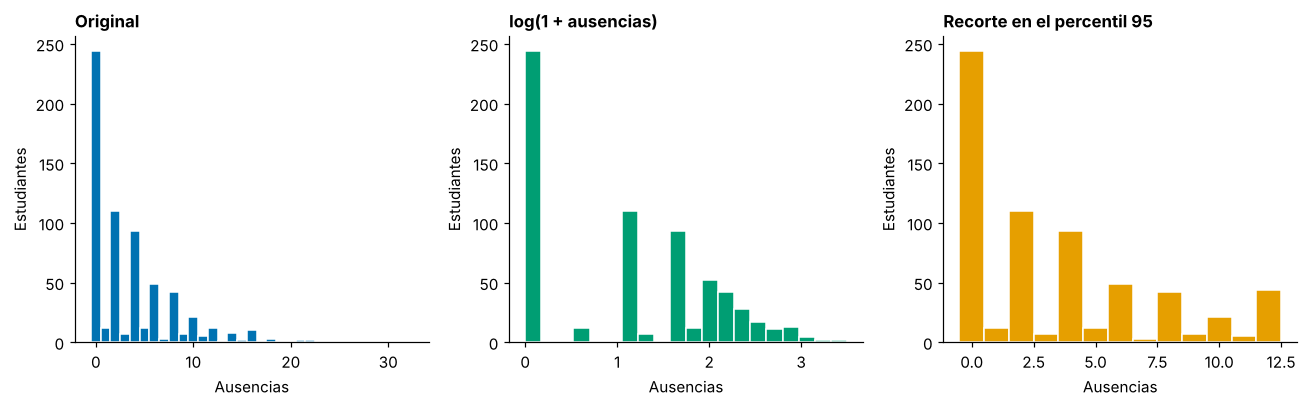

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
ejes[0].hist(ab, bins=np.arange(-0.5, ab.max() + 1.5, 1), color=AZUL, edgecolor="white"); ejes[0].set_title("Original")
ejes[1].hist(np.log1p(ab), bins=20, color=VERDE, edgecolor="white"); ejes[1].set_title("log(1 + ausencias)")
ejes[2].hist(ab.clip(upper=p95), bins=np.arange(-0.5, p95 + 1.5, 1), color=AMARILLO, edgecolor="white"); ejes[2].set_title(f"Recorte en el percentil 95")
for ax in ejes: ax.set_xlabel("Ausencias"); ax.set_ylabel("Estudiantes")
fig.tight_layout(); plt.show()

Figura 2. Distribución de las ausencias con los dos tratamientos. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La variable original tiene asimetría de 2,02, curtosis de 5,78 y 21 atípicos según el RIC. Con el logaritmo la asimetría baja a 0,18, la curtosis a -1,25 y no queda ningún atípico, y se conservan todos los datos y su orden. El recorte en el percentil 95 (12 ausencias) elimina los atípicos, pero deja una asimetría de 0,97, sustituye todos los valores entre 13 y 32 por 12 y, sobre todo, el límite de 12 sería un parámetro aprendido de los datos, que habría que calcular solo con el entrenamiento. Se elige la transformación logarítmica, que además no aprende nada de los datos y por eso se puede aplicar antes de la partición sin riesgo de fuga.

### 4.5 Resumen de decisiones de limpieza

| Situación | Evidencia | Decisión | Momento en que se aplica |
|---|---|---|---|
| 15 notas finales iguales a cero | Concentradas en la escuela MS, sin ausencias, patrón de abandono (secciones 4.1 y 4.2) | Indicador sin_nota_final; excluir de la regresión y conservar en la clasificación | Antes de la partición (regla fija) |
| Un G1 igual a cero con G3 positivo | Caso aislado, incoherente con G2 y G3 | Marcar como faltante e imputar con la mediana de G1 calculada solo con entrenamiento | Imputación dentro del pipeline |
| Ausencias con cola larga | Fuerte asimetría positiva | Transformación log(1 + x) | Antes de la partición (no aprende parámetros) |
| Edad de 21 y 22 años | Valores plausibles | Conservar | No aplica |
| Reprobaciones previas | La regla del RIC no es apropiada | Conservar | No aplica |
| Nominales y ordinales sin faltantes | 0 % de celdas vacías | Imputador de respaldo (moda) dentro del pipeline por si llegan datos nuevos incompletos | Pipeline |

Tabla 4. Decisiones de limpieza e imputación. Fuente: elaboración propia.

Sobre la imputación en general: como el archivo no tiene celdas vacías, no hay un mecanismo de falta que analizar en las variables originales, y aplicar KNNImputer o IterativeImputer sin necesidad sería agregar complejidad sin beneficio. Los imputadores quedan incluidos en el pipeline por dos razones: tratar el G1 marcado y permitir que el dashboard de la Fase 4 reciba datos de entrada incompletos sin fallar.

## 5. Ingeniería de variables

En la Fase 1 se propusieron variables derivadas a partir de lo observado. Se crean seis, todas calculadas fila por fila y sin parámetros aprendidos, por lo que se pueden hacer antes de la partición sin riesgo de fuga:

alcohol_total: suma del consumo de alcohol entre semana y de fin de semana (Dalc más Walc), que resume la exposición total al alcohol. educ_padres: promedio de los niveles educativos de la madre y del padre, ya que ambas variables estaban muy correlacionadas (rho de 0,65) y juntas describen el capital educativo del hogar. tiene_reprob: indicador de al menos una reprobación previa; en la Fase 1 se vio que el salto grande en G3 ocurre entre cero y una reprobación. log_ausencias: la transformación decidida en la sección 4.4. tendencia_notas: diferencia entre G2 y G1, que indica si el estudiante venía mejorando o empeorando. apoyo_total: cuántos de los tres apoyos (escuela, familia y clases pagas) recibe el estudiante, de 0 a 3.

In [8]:
df["alcohol_total"] = df["Dalc"] + df["Walc"]
df["educ_padres"] = (df["Medu"] + df["Fedu"]) / 2
df["tiene_reprob"] = (df["failures"] > 0).astype(int)
df["log_ausencias"] = np.log1p(df["absences"])
df["tendencia_notas"] = df["G2"] - df["G1"]
df["apoyo_total"] = (df["schoolsup"] == "yes").astype(int) + (df["famsup"] == "yes").astype(int) + (df["paid"] == "yes").astype(int)

derivadas = ["alcohol_total", "educ_padres", "tiene_reprob", "log_ausencias", "tendencia_notas", "apoyo_total"]
sc = df[df["G3"] > 0]
filas = []
for v in derivadas:
    ok_t = df[v].notna()
    rt, _ = stats.spearmanr(df.loc[ok_t, v], df.loc[ok_t, "G3"])
    ok_s = sc[v].notna()
    rs, ps = stats.spearmanr(sc.loc[ok_s, v], sc.loc[ok_s, "G3"])
    filas.append({"Variable derivada": v, "Mínimo": df[v].min(), "Máximo": df[v].max(),
                  "rho con G3 (todos)": round(rt, 3), "rho con G3 (sin ceros)": round(rs, 3), "Valor p (sin ceros)": f"{ps:.2e}"})
tabla_der = pd.DataFrame(filas).set_index("Variable derivada")
tabla_der

,Mínimo,Máximo,rho con G3 (todos),rho con G3 (sin ceros),Valor p (sin ceros)
Variable derivada,,,,,
alcohol_total,2.0,10.000000,-0.195,-0.188,1.95e-06
educ_padres,0.0,4.000000,0.284,0.279,8.43e-13
tiene_reprob,0.0,1.000000,-0.448,-0.430,7.32e-30
log_ausencias,0.0,3.496508,-0.159,-0.214,5.23e-08
tendencia_notas,-9.0,5.000000,0.148,0.107,6.93e-03
apoyo_total,0.0,3.000000,-0.035,-0.063,1.16e-01


Tabla 5. Variables derivadas y su correlación de Spearman con la nota final, con todos los estudiantes y sin los 15 ceros. Fuente: elaboración propia con datos de Cortez y Silva (2008).

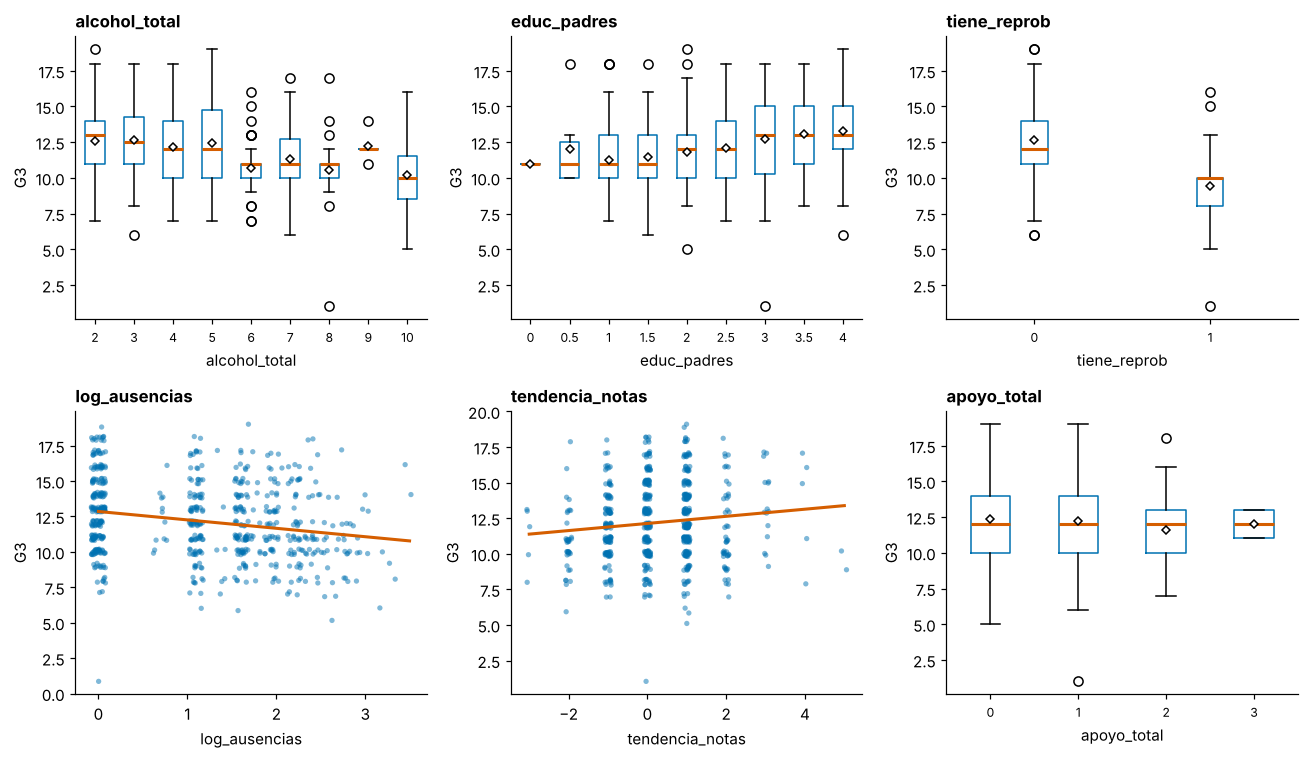

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(12, 7))
for ax, v in zip(ejes.flat, derivadas):
    d = sc[sc[v].notna()]
    if v in ("log_ausencias", "tendencia_notas"):
        rng = np.random.default_rng(SEMILLA)
        ax.scatter(d[v] + rng.uniform(-.08, .08, len(d)), d["G3"] + rng.uniform(-.2, .2, len(d)), s=12, alpha=.5, color=AZUL, edgecolor="none")
        m, b = np.polyfit(d[v], d["G3"], 1); xs = np.array([d[v].min(), d[v].max()])
        ax.plot(xs, m * xs + b, color=NARANJA, lw=2)
    else:
        niv = sorted(d[v].unique())
        ax.boxplot([d.loc[d[v] == k, "G3"] for k in niv], showmeans=True, boxprops=dict(color=AZUL), medianprops=dict(color=NARANJA, lw=2),
                   meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=4))
        ax.set_xticks(range(1, len(niv) + 1)); ax.set_xticklabels([f"{k:g}" for k in niv], fontsize=8)
    ax.set_title(v); ax.set_xlabel(v); ax.set_ylabel("G3")
fig.tight_layout(); plt.show()

Figura 3. Nota final (sin los 15 ceros) frente a cada variable derivada. En los diagramas de dispersión se añadió una pequeña dispersión aleatoria y la recta ajustada; en los de caja el rombo es la media. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Con los 15 ceros fuera, la variable derivada más asociada a la nota final es tiene_reprob (rho de -0,430), muy parecida a las reprobaciones originales; en la Figura 3 se ve que la media de G3 baja varios puntos con solo una reprobación. educ_padres (0,279) queda casi igual que la educación de la madre sola (0,284), pero resume en una variable a dos que estaban muy correlacionadas. alcohol_total (-0,188) no mejora al consumo entre semana por sí solo (-0,208), aunque aporta una medida única de la exposición. log_ausencias mejora de -0,159 a -0,214 cuando se excluyen los ceros, porque esos 15 estudiantes tenían cero ausencias y notas de cero, lo que diluía la relación; esto respalda la decisión de excluirlos de la regresión. tendencia_notas tiene una asociación débil (0,107, p de 0,007) y apoyo_total no es significativa (-0,063, p de 0,116); su signo negativo probablemente refleja que reciben apoyo quienes ya van mal, no que el apoyo perjudique. Las seis se conservan por ahora y en la Fase 3 la regularización y la importancia de variables mostrarán cuáles aportan. Hay que recordar que alcohol_total, educ_padres y tiene_reprob son combinaciones exactas de variables originales que también se mantienen, así que habrá colinealidad y por eso se usarán modelos regularizados.

## 6. Partición de los datos

Con las reglas fijas ya aplicadas, se hace la partición. Se usa 70 % para entrenamiento, 15 % para validación y 15 % para prueba, de forma estratificada por la variable aprobado para que la proporción de reprobados (15,4 %) se mantenga en los tres conjuntos. El entrenamiento sirve para ajustar los modelos y los transformadores, la validación para comparar modelos y ajustar hiperparámetros en la Fase 3, y la prueba se reserva para la evaluación final, sin usarla antes. Se hace una única partición sobre las 649 filas; en la regresión se descartan dentro de cada conjunto los estudiantes con sin_nota_final igual a 1, de modo que ambas tareas comparten los mismos estudiantes en cada partición y no se mezclan entre conjuntos.

In [10]:
idx_tr, idx_tmp = train_test_split(df.index, test_size=0.30, stratify=df["aprobado"], random_state=SEMILLA)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "aprobado"], random_state=SEMILLA)
df["particion"] = "entrenamiento"
df.loc[idx_va, "particion"] = "validación"
df.loc[idx_te, "particion"] = "prueba"
assert len(set(idx_tr) & set(idx_va)) == 0 and len(set(idx_tr) & set(idx_te)) == 0 and len(set(idx_va) & set(idx_te)) == 0

filas = []
for nom, idx in [("entrenamiento", idx_tr), ("validación", idx_va), ("prueba", idx_te)]:
    s = df.loc[idx]
    filas.append({"Partición": nom, "Estudiantes": len(s), "% del total": round(len(s) / len(df) * 100, 1),
                  "Reprobados": int((s["aprobado"] == 0).sum()), "% reprobados": round((s["aprobado"] == 0).mean() * 100, 1),
                  "Ceros en G3": int(s["sin_nota_final"].sum()), "Filas para regresión": int((s["G3"] > 0).sum()),
                  "Media de G3 (sin ceros)": round(s.loc[s["G3"] > 0, "G3"].mean(), 2)})
tabla_part = pd.DataFrame(filas).set_index("Partición")
tabla_part

,Estudiantes,% del total,Reprobados,% reprobados,Ceros en G3,Filas para regresión,Media de G3 (sin ceros)
Partición,,,,,,,
entrenamiento,454,70.0,70,15.4,8,446,12.09
validación,97,14.9,15,15.5,5,92,12.70
prueba,98,15.1,15,15.3,2,96,12.14


Tabla 6. Tamaño y composición de los conjuntos de entrenamiento, validación y prueba. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. La partición dejó 454 estudiantes en entrenamiento, 97 en validación y 98 en prueba. La proporción de reprobados es prácticamente igual en los tres conjuntos (15,4 %, 15,5 % y 15,3 %), que era el objetivo de la estratificación. Los ceros de G3 quedaron repartidos como 8, 5 y 2, y para la regresión quedan 446, 92 y 96 estudiantes. La media de G3 es un poco mayor en validación (12,70) que en entrenamiento (12,09), una diferencia que es de esperar con solo 92 estudiantes. Dos consecuencias para la Fase 3: en validación hay solo 15 reprobados, por lo que las métricas de clasificación son ruidosas (un estudiante cambia el recall en 6,7 puntos), y por eso la búsqueda de hiperparámetros se hará con validación cruzada sobre el entrenamiento, como pide la guía.

## 7. Codificación y escalamiento sin fuga de datos

### 7.1 Conjuntos de variables

Se definen dos conjuntos de variables predictoras, porque en la Fase 1 se vio que G1 y G2 casi determinan a G3. El conjunto completo incluye G1, G2 y la tendencia entre ambas. El conjunto sin notas las excluye y sirve para ver qué tan bien se puede predecir con información de contexto y hábitos, que es lo que permitiría intervenir temprano. En ambos casos se reemplazan las ausencias originales por su logaritmo, y se excluyen G3, aprobado, estado, sin_nota_final y particion.

Las variables ordinales se tratan como numéricas (con la simplificación que se explicó en la Fase 1), las nominales se codifican con one-hot (con drop if_binary, para que las variables de dos categorías queden en una sola columna) y las numéricas se estandarizan con StandardScaler. Todo esto se arma dentro de un ColumnTransformer que, junto con los imputadores, se ajusta únicamente con el conjunto de entrenamiento.

In [11]:
num_base = ["age", "failures", "log_ausencias"] + ordinales + ["alcohol_total", "educ_padres", "tiene_reprob", "apoyo_total"]
notas = ["G1", "G2", "tendencia_notas"]
cols_completo = num_base + notas
cols_sin_notas = num_base

def construir_preprocesador(num_cols, cat_cols=nominales):
    num = Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())])
    cat = Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

X_tr, X_va = df.loc[idx_tr, cols_completo + nominales], df.loc[idx_va, cols_completo + nominales]
pre = construir_preprocesador(cols_completo)
Z_tr = pre.fit_transform(X_tr)      # se ajusta SOLO con entrenamiento
Z_va = pre.transform(X_va)          # validación solo se transforma
nombres = pre.get_feature_names_out()
print("Conjunto completo:", len(cols_completo), "numéricas +", len(nominales), "categóricas ->", Z_tr.shape[1], "columnas tras la codificación")
print("Conjunto sin notas:", len(cols_sin_notas), "numéricas +", len(nominales), "categóricas ->", construir_preprocesador(cols_sin_notas).fit_transform(df.loc[idx_tr, cols_sin_notas + nominales]).shape[1], "columnas")
print("Forma de entrenamiento:", Z_tr.shape, "| validación:", Z_va.shape)
print("Valores faltantes tras el pipeline:", int(np.isnan(Z_tr).sum() + np.isnan(Z_va).sum()))

Conjunto completo: 20 numéricas + 17 categóricas -> 50 columnas tras la codificación
Conjunto sin notas: 17 numéricas + 17 categóricas -> 47 columnas
Forma de entrenamiento: (454, 50) | validación: (97, 50)
Valores faltantes tras el pipeline: 0


### 7.2 Comprobación de que no hay fuga

Una forma directa de verificar que el escalador aprendió solo del entrenamiento es comparar los parámetros que guardó con las medias del entrenamiento y con las de todos los datos. Si coinciden con las primeras y no con las segundas, no hubo fuga. Además, en el conjunto de entrenamiento las variables escaladas deben tener media 0 y desviación 1, mientras que en validación solo se aproximan.

In [12]:
esc = pre.named_transformers_["num"].named_steps["escalador"]
num_nombres = cols_completo
ver = pd.DataFrame({
    "Media guardada por el escalador": esc.mean_,
    "Media del entrenamiento": X_tr[num_nombres].mean().values,
    "Media de todos los datos": df[num_nombres].mean().values,
}, index=num_nombres)
ver["Diferencia con entrenamiento"] = (ver.iloc[:, 0] - ver.iloc[:, 1]).abs()
ver["Diferencia con todos los datos"] = (ver.iloc[:, 0] - ver.iloc[:, 2]).abs()
ver = ver.loc[["age", "failures", "log_ausencias", "G1", "G2", "tendencia_notas"]].round(4)
n_n = len(num_nombres)
print("Entrenamiento: media máxima en valor absoluto %.4f | desviación entre %.3f y %.3f" % (np.abs(Z_tr[:, :n_n].mean(0)).max(), Z_tr[:, :n_n].std(0).min(), Z_tr[:, :n_n].std(0).max()))
print("Validación:    media máxima en valor absoluto %.4f | desviación entre %.3f y %.3f" % (np.abs(Z_va[:, :n_n].mean(0)).max(), Z_va[:, :n_n].std(0).min(), Z_va[:, :n_n].std(0).max()))
ver

Entrenamiento: media máxima en valor absoluto 0.0000 | desviación entre 1.000 y 1.000
Validación:    media máxima en valor absoluto 0.2080 | desviación entre 0.807 y 1.274


,Media guardada por el escalador,Media del entrenamiento,Media de todos los datos,Diferencia con entrenamiento,Diferencia con todos los datos
age,16.7159,16.7159,16.7442,0.0000,0.0284
failures,0.2357,0.2357,0.2219,0.0000,0.0138
log_ausencias,1.0876,1.0876,1.0886,0.0000,0.0010
G1,11.3987,11.3996,11.4167,0.0009,0.0180
G2,11.5507,11.5507,11.5701,0.0000,0.0194
tendencia_notas,0.1520,0.1523,0.1543,0.0003,0.0023


Tabla 7. Parámetros del escalador frente a las medias del entrenamiento y de todos los datos. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Las medias que guardó el escalador coinciden con las del entrenamiento (diferencia de 0,0000 en casi todas) y no con las de todos los datos, de las que se separan entre 0,001 y 0,028. Las diferencias de 0,0009 en G1 y de 0,0003 en tendencia_notas se deben a que el escalador recibe los datos ya imputados, y la estudiante con G1 faltante entra con la mediana. En el entrenamiento las variables escaladas tienen media 0 y desviación 1, mientras que en validación la media llega a 0,208 y la desviación va de 0,807 a 1,274, que es lo esperado cuando validación solo se transforma con los parámetros del entrenamiento. Tras la codificación quedan 50 columnas en el conjunto completo (20 numéricas y 30 de las categóricas con one-hot) y 47 en el conjunto sin notas, sin ningún faltante. Al meter el pipeline completo dentro de cada modelo, también en la validación cruzada de la Fase 3 los transformadores se reajustarán en cada pliegue.

## 8. Modelo base (baseline)

### 8.1 Regresión

Para la regresión se evalúan tres referencias, todas con filas de nota real (G3 mayor que 0): la media de entrenamiento como predicción constante (el piso más bajo posible), una regresión lineal simple con G2 (la variable más correlacionada) y una regresión lineal simple con las reprobaciones previas, que es la mejor variable de contexto y sirve de referencia para el escenario sin notas. Los modelos se ajustan con entrenamiento y se evalúan en entrenamiento y validación.

In [13]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def met_reg(y, p): return {"R2": r2_score(y, p), "RMSE": rmse(y, p), "MAE": mean_absolute_error(y, p)}

tr_r = df.loc[idx_tr][df.loc[idx_tr, "G3"] > 0]
va_r = df.loc[idx_va][df.loc[idx_va, "G3"] > 0]
modelos_reg = {"Media (constante)": (DummyRegressor(strategy="mean"), ["G2"]),
               "Lineal simple: G2": (LinearRegression(), ["G2"]),
               "Lineal simple: reprobaciones previas": (LinearRegression(), ["failures"])}
filas, ajustados = [], {}
for nom, (mod, cols) in modelos_reg.items():
    mod.fit(tr_r[cols], tr_r["G3"]); ajustados[nom] = (mod, cols)
    for conj, d in [("entrenamiento", tr_r), ("validación", va_r)]:
        filas.append({"Modelo": nom, "Conjunto": conj, **met_reg(d["G3"], mod.predict(d[cols]))})
res_reg = pd.DataFrame(filas)
tabla_reg = res_reg.set_index(["Modelo", "Conjunto"]).round(3)
print("Estudiantes en entrenamiento:", len(tr_r), "| en validación:", len(va_r))
tabla_reg

Estudiantes en entrenamiento: 446 | en validación: 92


R2   RMSE    MAE
Modelo                               Conjunto                          
Media (constante)                    entrenamiento  0.000  2.669  2.148
                                     validación    -0.046  2.868  2.346
Lineal simple: G2                    entrenamiento  0.868  0.969  0.717
                                     validación     0.858  1.055  0.761
Lineal simple: reprobaciones previas entrenamiento  0.155  2.454  1.982
                                     validación     0.117  2.636  2.131

Tabla 8. Modelos base de regresión sobre la nota final. Fuente: elaboración propia con datos de Cortez y Silva (2008).

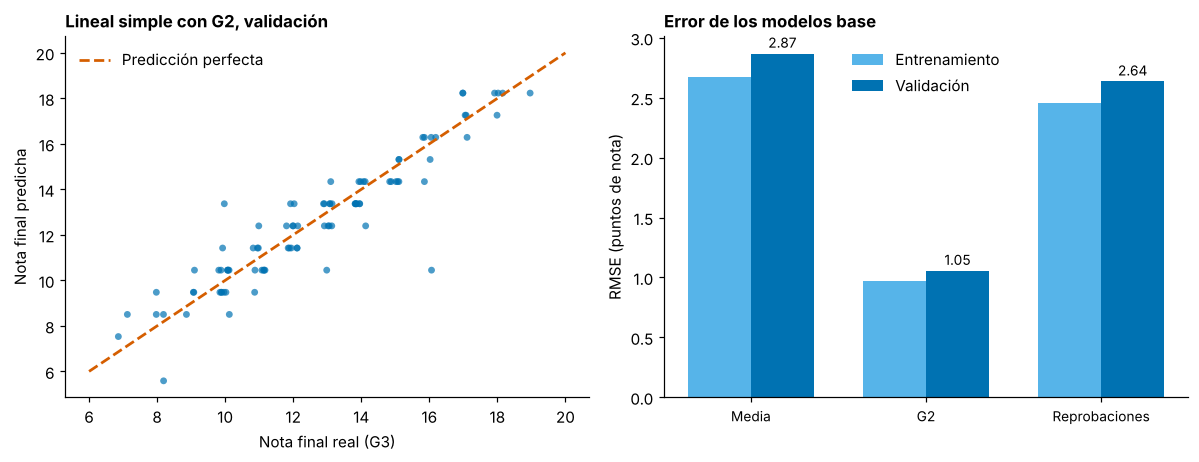

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
mod, cols = ajustados["Lineal simple: G2"]
pred = mod.predict(va_r[cols])
rng = np.random.default_rng(SEMILLA)
ax1.scatter(va_r["G3"] + rng.uniform(-.2, .2, len(va_r)), pred, s=20, alpha=.7, color=AZUL, edgecolor="none")
lim = [va_r["G3"].min() - 1, va_r["G3"].max() + 1]
ax1.plot(lim, lim, color=NARANJA, lw=1.8, ls="--", label="Predicción perfecta")
ax1.set_xlabel("Nota final real (G3)"); ax1.set_ylabel("Nota final predicha"); ax1.set_title("Lineal simple con G2, validación"); ax1.legend()

v = res_reg[res_reg["Conjunto"] == "validación"].set_index("Modelo")["RMSE"]
t = res_reg[res_reg["Conjunto"] == "entrenamiento"].set_index("Modelo")["RMSE"]
x = np.arange(len(v)); w = 0.36
ax2.bar(x - w / 2, t.values, w, color=CELESTE, label="Entrenamiento")
ax2.bar(x + w / 2, v.values, w, color=AZUL, label="Validación")
for i, val in enumerate(v.values): ax2.text(i + w / 2, val + 0.05, f"{val:.2f}", ha="center", fontsize=9)
ax2.set_xticks(x); ax2.set_xticklabels(["Media", "G2", "Reprobaciones"], fontsize=9)
ax2.set_ylabel("RMSE (puntos de nota)"); ax2.set_title("Error de los modelos base"); ax2.legend()
fig.tight_layout(); plt.show()

Figura 4. Predicción de la regresión simple con G2 en validación y comparación del error de los tres modelos base. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Predecir siempre la media del entrenamiento da un R² de -0,046 en validación (RMSE de 2,87): es incluso peor que la media propia de validación porque esta es algo más alta, y fija el piso. La regresión simple con G2 reduce el RMSE a 1,055 puntos en validación (R² de 0,858, MAE de 0,761), con una brecha pequeña respecto al entrenamiento (R² de 0,868 y RMSE de 0,969), así que no hay señal de sobreajuste. Con las reprobaciones previas como única variable el RMSE es de 2,64 en validación y el R² de 0,117, apenas un 8 % mejor que la media; esa es la referencia del escenario sin notas y muestra que el contexto por sí solo, con una variable, explica muy poco de la nota final.

Para documentar el efecto de la decisión sobre los ceros se entrena el modelo simple con G2 de dos formas, con y sin los 15 casos en el entrenamiento, y se evalúa en validación con y sin los casos de cero.

In [15]:
tr_con = df.loc[idx_tr]; va_con = df.loc[idx_va]
filas = []
for nom_tr, dtr in [("Entrenado sin ceros (decisión adoptada)", tr_r), ("Entrenado con ceros", tr_con)]:
    m = LinearRegression().fit(dtr[["G2"]], dtr["G3"])
    for nom_va, dva in [("Validación sin ceros", va_r), ("Validación con ceros", va_con)]:
        filas.append({"Entrenamiento": nom_tr, "Evaluación": nom_va, "Pendiente": round(m.coef_[0], 3),
                      **{k: round(v, 3) for k, v in met_reg(dva["G3"], m.predict(dva[["G2"]])).items()}})
pd.DataFrame(filas).set_index(["Entrenamiento", "Evaluación"])

Pendiente  \
Entrenamiento                           Evaluación                        
Entrenado sin ceros (decisión adoptada) Validación sin ceros      0.973   
                                        Validación con ceros      0.973   
Entrenado con ceros                     Validación sin ceros      1.018   
                                        Validación con ceros      1.018   

                                                                 R2   RMSE  \
Entrenamiento                           Evaluación                           
Entrenado sin ceros (decisión adoptada) Validación sin ceros  0.858  1.055   
                                        Validación con ceros  0.843  1.550   
Entrenado con ceros                     Validación sin ceros  0.849  1.088   
                                        Validación con ceros  0.845  1.540   

                                                                MAE  
Entrenamiento                           Evaluación                   
Entrenado sin ceros (decisión adoptada) Validación sin ceros  0.761  
                                        Validación con ceros  0.909  
Entrenado con ceros                     Validación sin ceros  0.782  
                                        Validación con ceros  0.905

Tabla 9. Efecto de incluir o excluir los ceros en el modelo simple con G2. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. Entrenar sin los ceros da un RMSE de 1,055 sobre los estudiantes con nota real, contra 1,088 si se entrena con ellos, y la pendiente de la recta sube de 0,973 a 1,018 porque los ceros jalan la línea. Al evaluar incluyendo los ceros de validación el RMSE sube a 1,55 en ambos casos, un 47 % más, solo por cinco estudiantes: ningún modelo basado en G2 puede anticipar un abandono. Es decir, excluirlos mejora un poco el ajuste para los estudiantes con nota real y no empeora nada en el resto, y el riesgo de abandono se aborda mejor desde la clasificación, donde sí se conservan.

### 8.2 Clasificación

Para la clasificación se toma como clase positiva reprobado (1 si G3 es menor que 10), y se usan las 649 filas. Se evalúan cuatro referencias: un clasificador que siempre predice la clase mayoritaria (el piso), una regresión logística básica con G2 como única variable, y la regresión logística con todas las variables preprocesadas, con el conjunto completo y con el conjunto sin notas. En las tres regresiones logísticas se usa class_weight igual a balanced, que le da más peso a la clase minoritaria sin generar datos sintéticos. Con una proporción de 15,4 % de reprobados el desbalance es moderado y no severo, y este ajuste es suficiente por ahora; si en la Fase 3 el recall de la clase reprobado resulta insuficiente se probará SMOTE solo sobre el entrenamiento.

In [16]:
y_tr = 1 - df.loc[idx_tr, "aprobado"]; y_va = 1 - df.loc[idx_va, "aprobado"]   # 1 = reprobado (clase positiva)

def met_clf(y, p, proba):
    return {"Exactitud": accuracy_score(y, p), "Precisión": precision_score(y, p, zero_division=0),
            "Recall": recall_score(y, p, zero_division=0), "F1": f1_score(y, p, zero_division=0), "AUC": roc_auc_score(y, proba)}

lr = lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA)
modelos_clf = {
    "Clase mayoritaria (Dummy)": (DummyClassifier(strategy="most_frequent"), ["G2"]),
    "Logística simple: G2": (Pipeline([("esc", StandardScaler()), ("lr", lr())]), ["G2"]),
    "Logística, conjunto sin notas": (Pipeline([("pre", construir_preprocesador(cols_sin_notas)), ("lr", lr())]), cols_sin_notas + nominales),
    "Logística, conjunto completo": (Pipeline([("pre", construir_preprocesador(cols_completo)), ("lr", lr())]), cols_completo + nominales),
}
filas, ajustados_clf = [], {}
for nom, (mod, cols) in modelos_clf.items():
    mod.fit(df.loc[idx_tr, cols], y_tr); ajustados_clf[nom] = (mod, cols)
    for conj, idx, y in [("entrenamiento", idx_tr, y_tr), ("validación", idx_va, y_va)]:
        Xc = df.loc[idx, cols]
        filas.append({"Modelo": nom, "Conjunto": conj, **met_clf(y, mod.predict(Xc), mod.predict_proba(Xc)[:, 1])})
res_clf = pd.DataFrame(filas)
tabla_clf = res_clf.set_index(["Modelo", "Conjunto"]).round(3)
tabla_clf

Exactitud  Precisión  Recall  \
Modelo                        Conjunto                                      
Clase mayoritaria (Dummy)     entrenamiento      0.846      0.000   0.000   
                              validación         0.845      0.000   0.000   
Logística simple: G2          entrenamiento      0.896      0.619   0.857   
                              validación         0.918      0.667   0.933   
Logística, conjunto sin notas entrenamiento      0.846      0.500   0.871   
                              validación         0.680      0.265   0.600   
Logística, conjunto completo  entrenamiento      0.934      0.704   0.986   
                              validación         0.887      0.591   0.867   

                                                F1    AUC  
Modelo                        Conjunto                     
Clase mayoritaria (Dummy)     entrenamiento  0.000  0.500  
                              validación     0.000  0.500  
Logística simple: G2          entrenamiento  0.719  0.955  
                              validación     0.778  0.977  
Logística, conjunto sin notas entrenamiento  0.635  0.921  
                              validación     0.367  0.726  
Logística, conjunto completo  entrenamiento  0.821  0.987  
                              validación     0.703  0.963

Tabla 10. Modelos base de clasificación (clase positiva: reprobado). Fuente: elaboración propia con datos de Cortez y Silva (2008).

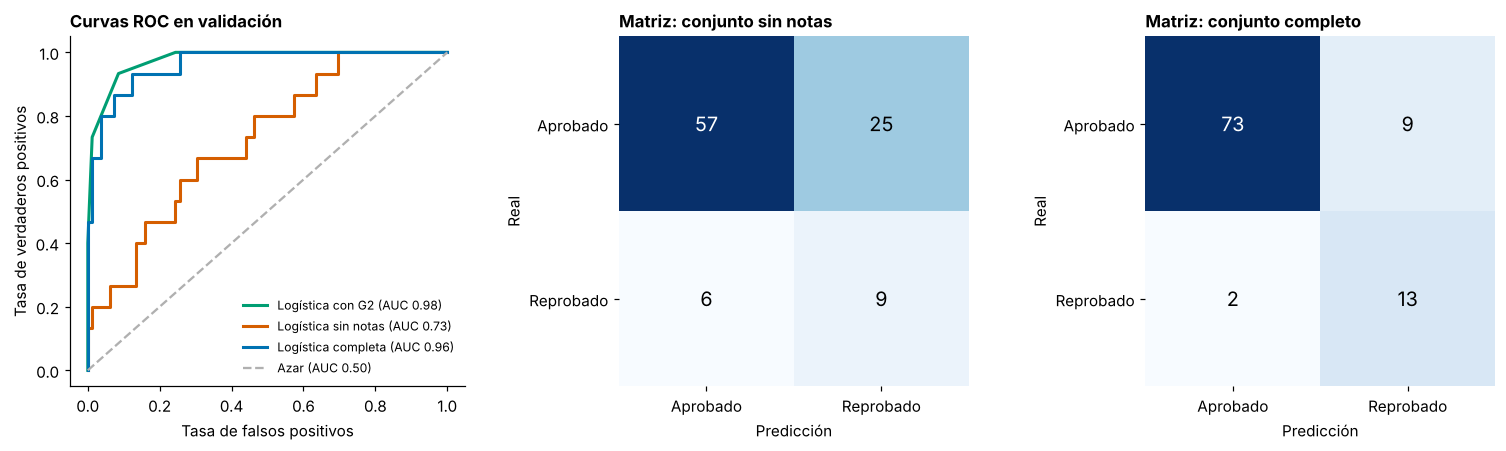

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
etiq = {"Logística simple: G2": "Logística con G2", "Logística, conjunto sin notas": "Logística sin notas", "Logística, conjunto completo": "Logística completa"}
col = {"Logística simple: G2": VERDE, "Logística, conjunto sin notas": NARANJA, "Logística, conjunto completo": AZUL}
for nom, c in col.items():
    mod, cols = ajustados_clf[nom]
    fpr, tpr, _ = roc_curve(y_va, mod.predict_proba(df.loc[idx_va, cols])[:, 1])
    auc = res_clf[(res_clf.Modelo == nom) & (res_clf.Conjunto == "validación")]["AUC"].iloc[0]
    ejes[0].plot(fpr, tpr, color=c, lw=2, label=f"{etiq[nom]} (AUC {auc:.2f})")
ejes[0].plot([0, 1], [0, 1], color=GRIS, ls="--", label="Azar (AUC 0.50)")
ejes[0].set_xlabel("Tasa de falsos positivos"); ejes[0].set_ylabel("Tasa de verdaderos positivos"); ejes[0].set_title("Curvas ROC en validación"); ejes[0].legend(fontsize=8, loc="lower right")
for ax, nom in zip(ejes[1:], ["Logística, conjunto sin notas", "Logística, conjunto completo"]):
    mod, cols = ajustados_clf[nom]
    cm = confusion_matrix(y_va, mod.predict(df.loc[idx_va, cols]))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Aprobado", "Reprobado"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Aprobado", "Reprobado"])
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title(nom.replace("Logística, ", "Matriz: "))
    for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); plt.show()

Figura 5. Curvas ROC de las regresiones logísticas y matrices de confusión de los dos conjuntos de variables en validación. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Interpretación. El clasificador de la clase mayoritaria tiene una exactitud de 0,845 y un F1 de 0 (no detecta a ningún reprobado), lo que confirma que la exactitud no sirve como medida principal. La regresión logística simple con G2 alcanza en validación un F1 de 0,778, un recall de 0,933, una precisión de 0,667 y un AUC de 0,977. La logística con el conjunto completo no la supera: obtiene un F1 de 0,703 y un AUC de 0,963 en validación, con un F1 de 0,821 en entrenamiento, o sea con una brecha mayor, señal de que 50 columnas para 70 reprobados en entrenamiento son demasiadas para este modelo sin ajuste. Parte de esa diferencia puede ser ruido por los 15 reprobados de validación. El escenario sin notas es el más exigente: F1 de 0,367, recall de 0,600, precisión de 0,265 y AUC de 0,726 en validación, frente a F1 de 0,635 y AUC de 0,921 en entrenamiento. La matriz de confusión muestra que detecta 9 de los 15 reprobados al costo de 25 falsos positivos. El AUC de 0,726 indica que hay señal real en el contexto y los hábitos, pero modesta, y la brecha con el entrenamiento indica sobreajuste. Ese es precisamente el escenario con más margen de mejora para la Fase 3.

### 8.3 Umbrales de rendimiento para la Fase 3

Con los resultados anteriores se fijan las referencias que deberán superar los modelos de la Fase 3. Se reportan siempre en validación, y por separado para el escenario con notas parciales y para el escenario sin ellas.

In [18]:
def v(res, modelo, met): return res[(res.Modelo == modelo) & (res.Conjunto == "validación")][met].iloc[0]
umbrales = pd.DataFrame([
    {"Tarea": "Regresión", "Escenario": "Con notas parciales", "Modelo base": "Lineal simple: G2", "Métrica": "RMSE (validación)", "Valor a superar": v(res_reg, "Lineal simple: G2", "RMSE")},
    {"Tarea": "Regresión", "Escenario": "Con notas parciales", "Modelo base": "Lineal simple: G2", "Métrica": "R2 (validación)", "Valor a superar": v(res_reg, "Lineal simple: G2", "R2")},
    {"Tarea": "Regresión", "Escenario": "Sin notas parciales", "Modelo base": "Lineal simple: reprobaciones previas", "Métrica": "RMSE (validación)", "Valor a superar": v(res_reg, "Lineal simple: reprobaciones previas", "RMSE")},
    {"Tarea": "Clasificación", "Escenario": "Con notas parciales", "Modelo base": "Logística simple: G2", "Métrica": "F1 reprobado (validación)", "Valor a superar": v(res_clf, "Logística simple: G2", "F1")},
    {"Tarea": "Clasificación", "Escenario": "Con notas parciales", "Modelo base": "Logística simple: G2", "Métrica": "AUC (validación)", "Valor a superar": v(res_clf, "Logística simple: G2", "AUC")},
    {"Tarea": "Clasificación", "Escenario": "Con notas parciales (referencia)", "Modelo base": "Logística, conjunto completo", "Métrica": "F1 reprobado (validación)", "Valor a superar": v(res_clf, "Logística, conjunto completo", "F1")},
    {"Tarea": "Clasificación", "Escenario": "Sin notas parciales", "Modelo base": "Logística, conjunto sin notas", "Métrica": "F1 reprobado (validación)", "Valor a superar": v(res_clf, "Logística, conjunto sin notas", "F1")},
    {"Tarea": "Clasificación", "Escenario": "Sin notas parciales", "Modelo base": "Logística, conjunto sin notas", "Métrica": "AUC (validación)", "Valor a superar": v(res_clf, "Logística, conjunto sin notas", "AUC")},
]).set_index(["Tarea", "Escenario", "Modelo base", "Métrica"])
umbrales["Valor a superar"] = umbrales["Valor a superar"].round(3)
umbrales

Valor a superar
Tarea         Escenario                        Modelo base                          Métrica                                   
Regresión     Con notas parciales              Lineal simple: G2                    RMSE (validación)                    1.055
                                                                                    R2 (validación)                      0.858
              Sin notas parciales              Lineal simple: reprobaciones previas RMSE (validación)                    2.636
Clasificación Con notas parciales              Logística simple: G2                 F1 reprobado (validación)            0.778
                                                                                    AUC (validación)                     0.977
              Con notas parciales (referencia) Logística, conjunto completo         F1 reprobado (validación)            0.703
              Sin notas parciales              Logística, conjunto sin notas        F1 reprobado (validación)            0.367
                                                                                    AUC (validación)                     0.726

Tabla 11. Umbrales de rendimiento mínimo para los modelos de la Fase 3. Fuente: elaboración propia con datos de Cortez y Silva (2008).

## 9. Conclusiones y preparación de la Fase 3

En esta fase se prepararon los datos de forma coherente con lo que se dejó planteado en la Fase 1. Se resolvió el problema de los datos faltantes disfrazados: los 15 ceros de la nota final no se imputaron, porque el análisis del mecanismo mostró que dependen de la escuela, la nota inicial, las reprobaciones y la edad (no es MCAR) y es probable que reflejen abandonos (MNAR). Se excluyen de la regresión y se conservan en la clasificación como reprobados, y el efecto se documentó. El G1 igual a cero se trató como un error de captura y se imputa con la mediana del entrenamiento. Las ausencias se transformaron con el logaritmo, y se crearon seis variables derivadas. Los datos se partieron de forma estratificada en 454, 97 y 98 estudiantes, y se comprobó que el escalador solo aprendió del entrenamiento.

Los modelos base fijan el piso para la Fase 3. En regresión, la referencia con notas parciales es la lineal simple con G2 (RMSE de 1,055 y R² de 0,858 en validación) y, sin notas, la lineal simple con reprobaciones previas (RMSE de 2,636). En clasificación, la referencia con notas es la logística simple con G2 (F1 de 0,778 y AUC de 0,977) y, sin notas, la logística con el conjunto sin notas (F1 de 0,367 y AUC de 0,726). Los resultados indican que casi todo el poder predictivo viene de G2, y que el desafío real está en el escenario sin notas, que es el que serviría para intervenir temprano.

Lo que sigue para la Fase 3:

1. Entrenar los modelos de regresión (regularizada y de ensambles), los de clasificación (dos algoritmos, más el perceptrón multicapa en PyTorch) y el agrupamiento (K-Means con codo y silueta, más DBSCAN o jerárquico), siempre comparando contra los umbrales de la tabla 11 y en los dos escenarios.
2. Buscar hiperparámetros con validación cruzada estratificada sobre el entrenamiento, dado que la validación tiene solo 15 reprobados, y volver a usar la validación y la prueba solo para la comparación final.
3. Evaluar si SMOTE mejora el recall de la clase reprobado, aplicado únicamente dentro de cada pliegue de entrenamiento.
4. Para el agrupamiento se usarán las variables de hábitos y contexto (sin notas ni variables derivadas de ellas), estandarizadas con los parámetros del entrenamiento.
5. Analizar la importancia de las variables con SHAP o importancia por permutación.

Limitaciones a tener presentes: los ceros se interpretaron como abandonos con base en patrones de los datos y no en documentación del archivo; la validación es pequeña y sus métricas son ruidosas; y los datos de dos escuelas de Portugal limitan la generalización. Los datos preparados y la configuración quedaron guardados en data/processed para continuar en la Fase 3.

In [19]:
# Se guardan los datos preparados y la configuración para usarlos en la Fase 3
os.makedirs("data/processed", exist_ok=True)
columnas_salida = (["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob", "reason", "guardian", "schoolsup", "famsup", "paid",
                    "activities", "nursery", "higher", "internet", "romantic"] + ["age", "failures", "absences"] + ordinales + ["G1", "G2", "G3"]
                   + derivadas + ["sin_nota_final", "aprobado", "particion"])
df[columnas_salida].to_csv("data/processed/student_por_fase2.csv", index=True, index_label="fila")
config = {"semilla": SEMILLA, "cols_completo": cols_completo, "cols_sin_notas": cols_sin_notas, "nominales": nominales,
          "derivadas": derivadas, "particion": {"entrenamiento": len(idx_tr), "validacion": len(idx_va), "prueba": len(idx_te)}}
json.dump(config, open("data/processed/config_fase2.json", "w"), ensure_ascii=False, indent=1)
print("Guardado: data/processed/student_por_fase2.csv", df[columnas_salida].shape, "y config_fase2.json")

Guardado: data/processed/student_por_fase2.csv (649, 42) y config_fase2.json


## 10. Referencias

Cortez, P. (2008). Student Performance [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Cortez, P., y Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito y J. Teixeira (Eds.), Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008) (pp. 5-12). EUROSIS.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Kaufman, S., Rosset, S., Perlich, C., y Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. ACM Transactions on Knowledge Discovery from Data, 6(4), 1-21.

Little, R. J. A., y Rubin, D. B. (2019). Statistical analysis with missing data (3.ª ed.). Wiley.

Mann, H. B., y Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. The Annals of Mathematical Statistics, 18(1), 50-60.

McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56-61.

Okabe, M., e Ito, K. (2008). Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people. https://jfly.uni-koeln.de/color/

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825-2830.

Rubin, D. B. (1976). Inference and missing data. Biometrika, 63(3), 581-592.

Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261-272. https://doi.org/10.1038/s41592-019-0686-2